# 05 · Mapas interativos e exportação

**AgroGeo Analytics · Projeto 01**

> ⚠️ Os valores mapeados vêm de dados **sintéticos**. Os mapas servem para demonstrar a técnica.

## Objetivos
1. Mapa interativo (folium) com limite municipal, talhões coloridos por NDVI médio, tooltips e controle de camadas.
2. Sobrepor um **raster** (NDVI sintético) como imagem.
3. Mapa de **anomalia relativa**.
4. Exportar **GeoJSON** e **HTML** e validar os arquivos gerados.

In [1]:
import sys
from pathlib import Path
try:
    import agrogeo  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "agrogeo").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from agrogeo import config, gis, indices, zonal, timeseries as ts_lib, maps
from agrogeo.config import DATA_SAMPLE, OUTPUTS, CRS_GEO, CRS_UTM22S

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
SYNTH_NOTE = "DADOS SINTÉTICOS — ilustrativo, não é medição"
import folium, rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import matplotlib
muni = gpd.read_file(DATA_SAMPLE / "municipio_3538808.geojson")
tal = gpd.read_file(DATA_SAMPLE / "talhoes_sinteticos.geojson")
serie = pd.read_csv(DATA_SAMPLE / "serie_sintetica_ndvi_ndre.csv", parse_dates=["date"])
BASE = ("2021-01-01", "2022-12-31")

## 1. Tabela de atributos para o mapa

Combinamos geometria + estatísticas: área, NDVI médio dos **últimos 12 meses** da série, NDRE médio e anomalia relativa média no mesmo período.

In [2]:
ultimo = serie["date"].max()
janela = serie[serie["date"] > ultimo - pd.Timedelta(days=365)]
ndvi_m = janela.groupby("talhao_id")["ndvi"].mean().rename("ndvi_medio_12m")
ndre_m = janela.groupby("talhao_id")["ndre"].mean().rename("ndre_medio_12m")
rel = ts_lib.relative_anomaly(serie, "ndvi", window_days=30, baseline=BASE)
anom_m = rel[rel["date"] > ultimo - pd.Timedelta(days=365)].groupby("talhao_id")["anom_rel"].mean().rename("anom_rel_12m")
g = tal.merge(ndvi_m, on="talhao_id").merge(ndre_m, on="talhao_id").merge(anom_m, on="talhao_id")
g["area_ha"] = gis.area_ha(g, CRS_UTM22S).round(2)
for c in ["ndvi_medio_12m", "ndre_medio_12m", "anom_rel_12m"]:
    g[c] = g[c].round(4)
print("Janela:", (ultimo - pd.Timedelta(days=365)).date(), "→", ultimo.date())
g.drop(columns="geometry").head()

Janela: 2024-01-01 → 2024-12-31


,talhao_id,nome,cultivar,ano_plantio,SINTETICO,ndvi_medio_12m,ndre_medio_12m,anom_rel_12m,area_ha
0,T01,Talhão sintético 01,Catuaí Vermelho,2014,True,0.7660,0.4334,-0.0003,8.30
1,T02,Talhão sintético 02,Mundo Novo,2019,True,0.6962,0.3900,-0.0092,9.61
2,T03,Talhão sintético 03,Arara,2009,True,0.6677,0.3747,-0.0040,9.70
3,T04,Talhão sintético 04,Catuaí Amarelo,2014,True,0.7515,0.4269,-0.0004,6.85
4,T05,Talhão sintético 05,Catuaí Vermelho,2013,True,0.6942,0.3892,0.0061,10.93


## 2. Mapa coroplético de NDVI médio

`maps.choropleth_talhoes` cria o mapa com camadas (OSM, CartoDB), limite municipal, legenda e tooltip. A escala de cores usa os extremos dos dados; para comparar mapas de períodos diferentes, **fixe `vmin`/`vmax`**.

In [3]:
m1 = maps.choropleth_talhoes(g, "ndvi_medio_12m", municipio=muni, title="NDVI médio (12 m) — SINTÉTICO",
                             tooltip_cols=["talhao_id", "cultivar", "area_ha", "ndvi_medio_12m", "ndre_medio_12m"])
m1

**Como usar:** passe o mouse sobre um talhão para ver os atributos; o botão de camadas liga/desliga OSM, limite municipal e talhões. Cores: vermelho = menor, verde = maior (dentro da faixa dos dados).

## 3. Raster sobreposto

O raster está em EPSG:31982; o Leaflet usa lat/lon (EPSG:4326) — reprojetamos o array com `rasterio.warp.reproject` e o colocamos como `ImageOverlay` com os limites corretos.


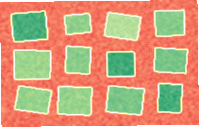

In [4]:
with rasterio.open(DATA_SAMPLE / "ndvi_sintetico.tif") as src:
    transform, w, h = calculate_default_transform(src.crs, CRS_GEO, src.width, src.height, *src.bounds)
    dst = np.full((h, w), np.nan, dtype="float32")
    reproject(source=rasterio.band(src, 1), destination=dst, src_transform=src.transform, src_crs=src.crs,
              dst_transform=transform, dst_crs=CRS_GEO, resampling=Resampling.bilinear, dst_nodata=np.nan)
    west, north = transform * (0, 0); east, south = transform * (w, h)

cmap = matplotlib.colormaps["RdYlGn"]; norm = matplotlib.colors.Normalize(0.2, 0.9)
rgba = cmap(norm(dst)); rgba[np.isnan(dst), 3] = 0
m2 = folium.Map(location=[(north + south) / 2, (east + west) / 2], zoom_start=14, tiles="OpenStreetMap")
folium.raster_layers.ImageOverlay(image=rgba, bounds=[[south, west], [north, east]], opacity=.75, name="NDVI sintético (raster)").add_to(m2)
folium.GeoJson(g, name="Talhões", style_function=lambda f: {"color": "#111", "weight": 1.5, "fill": False},
               tooltip=folium.GeoJsonTooltip(fields=["talhao_id", "cultivar"])).add_to(m2)
folium.LayerControl().add_to(m2)
m2

**Como ler:** a imagem mostra NDVI pixel a pixel (10 m); contornos pretos são os talhões. Verde-escuro = NDVI alto, amarelo/laranja = NDVI baixo (entorno). Em dados reais, a imagem de fundo ajuda a notar **heterogeneidade intra-talhão** que a média esconde.

## 4. Mapa de anomalia relativa (divergente)

Escala **divergente centrada em 0** (vermelho = abaixo dos vizinhos, azul = acima), simétrica para não distorcer a leitura.

In [5]:
lim = float(np.ceil(g["anom_rel_12m"].abs().max() * 100) / 100) or 0.05
m3 = maps.choropleth_talhoes(g, "anom_rel_12m", municipio=muni, cmap="RdBu", vmin=-lim, vmax=lim,
                             title="Anomalia relativa média (12 m) — SINTÉTICO",
                             tooltip_cols=["talhao_id", "cultivar", "anom_rel_12m"])
m3

## 5. Exportação e validação

In [6]:
out = config.OUTPUTS
p_geo = maps.export_geojson(g, out / "talhoes_resumo.geojson")
p1 = maps.export_html(m1, out / "mapa_ndvi_medio.html")
p2 = maps.export_html(m2, out / "mapa_raster_ndvi.html")
p3 = maps.export_html(m3, out / "mapa_anomalia_relativa.html")

chk = gpd.read_file(p_geo)
assert len(chk) == len(g) and chk.crs.to_epsg() == 4326 and "ndvi_medio_12m" in chk.columns
for p in (p1, p2, p3):
    print(f"{p.name}: {p.stat().st_size/1024:.0f} KB")
print("GeoJSON validado:", p_geo.name, chk.shape, "| CRS", chk.crs.to_string())

mapa_ndvi_medio.html: 21 KB
mapa_raster_ndvi.html: 48 KB
mapa_anomalia_relativa.html: 20 KB
GeoJSON validado: talhoes_resumo.geojson (12, 10) | CRS EPSG:4326


**Notas de exportação**
- GeoJSON (RFC 7946) deve estar em EPSG:4326 — `export_geojson` converte.
- O HTML usa tiles OpenStreetMap/CARTO via internet (abra com conexão). Respeite os termos de uso dos provedores de tiles e **mantenha a atribuição** exibida no mapa.
- Mapas do HTML com muitos polígonos ficam pesados; para regiões grandes, simplifique geometrias ou use tiles vetoriais.